<a href="https://colab.research.google.com/github/mdzubayereashraf/Ostad-AI-Engineering-Course-Assignments/blob/main/Assignmen_No_16(People_Flow_Detection_using_Object_Tracking_%26amp%3B_Heatmap_Visualization_%7C%7C_Object_Tracking_Project).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# People Flow Detection Using Object Tracking and Heatmap Visualization

## Project Overview

This project detects and tracks people in a video using a pretrained YOLO model and ByteTrack. It counts people crossing two horizontal lines to estimate incoming and outgoing movement. A heatmap is also generated to visualize areas where people frequently appear.

## Objectives

* Detect people using a pretrained YOLO model.
* Track detected people using unique IDs.
* Count people entering and leaving based on line-crossing events.
* Generate a heatmap of people's movement or presence.
* Save the processed video and heatmap as output files.


### **Install Required Libraries**

In [2]:
!pip install -q ultralytics opencv-python-headless matplotlib numpy

### **Video Download**

In [3]:
import os
import urllib.request

VIDEO_URL = "https://media.roboflow.com/supervision/video-examples/people-walking.mp4"
VIDEO_PATH = "/content/people-walking.mp4"

urllib.request.urlretrieve(VIDEO_URL, VIDEO_PATH)

print("Video downloaded:", os.path.exists(VIDEO_PATH))
print("File size (MB):", round(os.path.getsize(VIDEO_PATH) / (1024**2), 2))

Video downloaded: True
File size (MB): 7.25


### **Inspect the Video and Define Counting Lines**

First, we inspect the video's width, height, frame rate, and total number of frames.

We then define two horizontal counting lines:

**Upper line:** One-third of the video height.
**Lower line:** Two-thirds of the video height.

The lines are displayed on a sample frame to verify their positions before processing the complete video.

Width: 1920
Height: 1080
FPS: 25.0
Frame count: 341
Upper line y-coordinate: 360
Lower line y-coordinate: 720


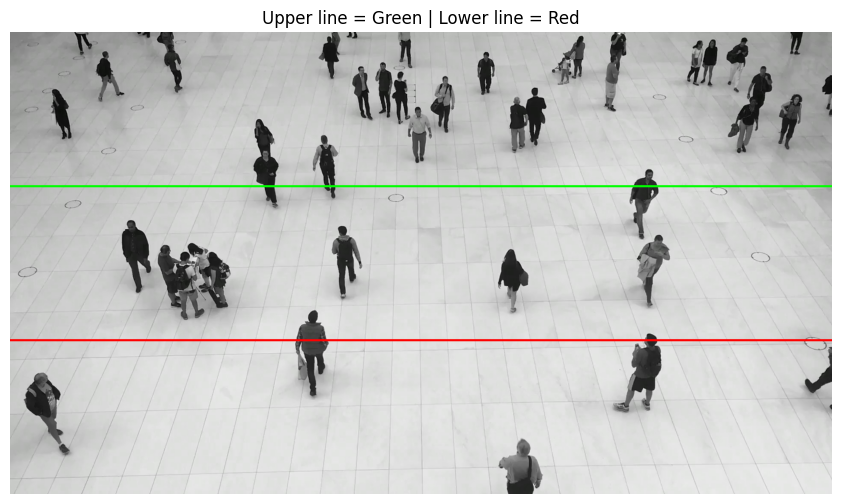

In [4]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError("Could not open the video.")

WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
FPS = cap.get(cv2.CAP_PROP_FPS)
FRAME_COUNT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.release()

# Horizontal counting lines
UPPER_LINE = HEIGHT // 3
LOWER_LINE = (2 * HEIGHT) // 3

print("Width:", WIDTH)
print("Height:", HEIGHT)
print("FPS:", FPS)
print("Frame count:", FRAME_COUNT)
print("Upper line y-coordinate:", UPPER_LINE)
print("Lower line y-coordinate:", LOWER_LINE)

# Preview the two lines on a video frame
cap = cv2.VideoCapture(VIDEO_PATH)
success, frame = cap.read()
cap.release()

if success:
    cv2.line(frame, (0, UPPER_LINE),
             (WIDTH, UPPER_LINE), (0, 255, 0), 3)

    cv2.line(frame, (0, LOWER_LINE),
             (WIDTH, LOWER_LINE), (0, 0, 255), 3)

    plt.figure(figsize=(12, 6))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("Upper line = Green | Lower line = Red")
    plt.axis("off")
    plt.show()

### **Load the Pretrained YOLO Model**

We use the pretrained YOLOv8n model to detect people in each video frame. The model is lightweight and suitable for object detection experiments.

We restrict detection to the person class and use ByteTrack to maintain tracking IDs across consecutive frames.


In [5]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO model loaded successfully.


### **Detect and Track People and Count IN/OUT Events**

In this step, we process the video frame by frame.

For each frame, the YOLO model detects people, while ByteTrack assigns tracking IDs to detected individuals. Bounding boxes and IDs are drawn on the video.

### **Counting Logic**

* **IN:** A tracked person's center moves from above the upper line to the line or below it.
* **OUT:** A tracked person's center moves from below the lower line to the line or above it.

The program displays the IN and OUT counters on the processed video and saves the final output as an MP4 file.


In [6]:
from collections import defaultdict
import numpy as np
import cv2
import os

OUTPUT_VIDEO = "/content/people_flow_output.mp4"
OUTPUT_HEATMAP = "/content/people_heatmap.png"

# Previous center position for each tracked person
previous_positions = {}

# Each ID is counted at most once in this simple implementation
counted_ids = {}

in_count = 0
out_count = 0

# Heatmap accumulator
heatmap = np.zeros((HEIGHT, WIDTH), dtype=np.float32)

cap = cv2.VideoCapture(VIDEO_PATH)

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    OUTPUT_VIDEO,
    fourcc,
    FPS if FPS > 0 else 25,
    (WIDTH, HEIGHT)
)

frame_number = 0

while cap.isOpened():
    success, frame = cap.read()

    if not success:
        break

    frame_number += 1

    # Detect and track people (COCO class 0 = person)
    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.25,
        verbose=False
    )

    result = results[0]

    # Draw upper and lower counting lines
    cv2.line(
        frame, (0, UPPER_LINE), (WIDTH, UPPER_LINE),
        (0, 255, 0), 2
    )
    cv2.line(
        frame, (0, LOWER_LINE), (WIDTH, LOWER_LINE),
        (0, 0, 255), 2
    )

    if result.boxes is not None and result.boxes.id is not None:
        boxes = result.boxes.xyxy.cpu().numpy()
        track_ids = result.boxes.id.int().cpu().tolist()

        for box, track_id in zip(boxes, track_ids):
            x1, y1, x2, y2 = map(int, box)

            # Bounding-box center
            cx = (x1 + x2) // 2
            cy = (y1 + y2) // 2

            # Accumulate presence intensity
            cv2.circle(heatmap, (cx, cy), 8, 1.0, -1)

            # Count a crossing only if this ID has not been counted
            if track_id in previous_positions:
                prev_x, prev_y = previous_positions[track_id]

                if track_id not in counted_ids:
                    # Top -> downward across upper line
                    if prev_y < UPPER_LINE <= cy:
                        in_count += 1
                        counted_ids[track_id] = "IN"

                    # Bottom -> upward across lower line
                    elif prev_y > LOWER_LINE >= cy:
                        out_count += 1
                        counted_ids[track_id] = "OUT"

            previous_positions[track_id] = (cx, cy)

            # Bounding box and tracking ID
            color = (255, 180, 0)
            cv2.rectangle(
                frame, (x1, y1), (x2, y2), color, 2
            )

            cv2.putText(
                frame, f"Person ID: {track_id}",
                (x1, max(y1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                color, 2
            )

    # Live counters
    cv2.rectangle(frame, (10, 10), (245, 90), (0, 0, 0), -1)

    cv2.putText(
        frame, f"IN: {in_count}",
        (20, 42), cv2.FONT_HERSHEY_SIMPLEX,
        0.8, (0, 255, 0), 2
    )

    cv2.putText(
        frame, f"OUT: {out_count}",
        (20, 75), cv2.FONT_HERSHEY_SIMPLEX,
        0.8, (0, 0, 255), 2
    )

    writer.write(frame)

cap.release()
writer.release()

print("Video processing complete.")
print("IN count:", in_count)
print("OUT count:", out_count)
print("Saved video:", OUTPUT_VIDEO)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 241ms
Prepared 1 package in 53ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Video processing complete.
IN count: 12
OUT count: 9
Saved video: /content/people_flow_output.mp4


### **Generate the People Heatmap**

We record the center point of each detected person's bounding box across video frames.

These points are accumulated in a heatmap. Gaussian blur is applied to smooth the accumulated values, and a color map is used to visualize areas with higher recorded activity.

The final heatmap is saved as a PNG image.


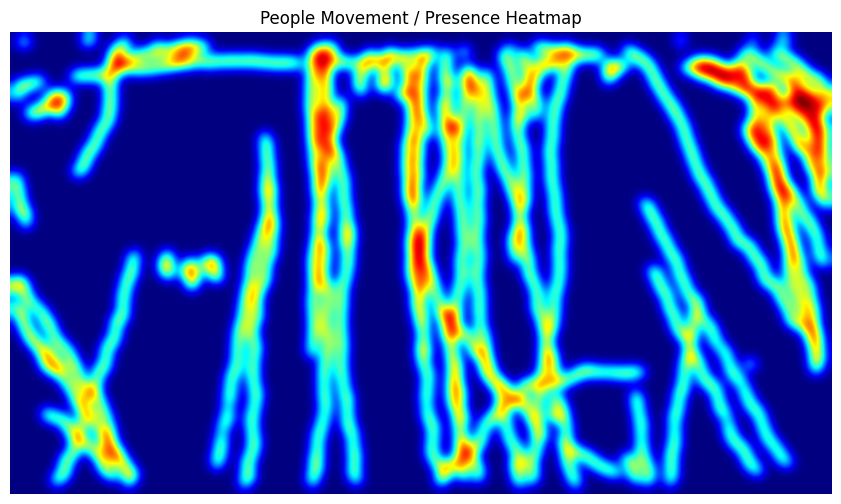

Heatmap saved: /content/people_heatmap.png


In [8]:
# Smooth the accumulated center-point heatmap
heatmap_blurred = cv2.GaussianBlur(
    heatmap, (0, 0), sigmaX=15, sigmaY=15
)

# Normalize to 0-255
heatmap_uint8 = cv2.normalize(
    heatmap_blurred,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Apply a color map
colored_heatmap = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

cv2.imwrite(OUTPUT_HEATMAP, colored_heatmap)

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(colored_heatmap, cv2.COLOR_BGR2RGB))
plt.title("People Movement / Presence Heatmap")
plt.axis("off")
plt.show()

print("Heatmap saved:", OUTPUT_HEATMAP)